# Meikural — Saraga Hindustani exploration

This notebook has not been executed. Run the cells yourself in order.

Install dependencies using `python -m pip install -r requirements.txt` in your virtual environment, then select that environment as the notebook kernel.

Goal: inspect labelled recordings and artists per raag before choosing classes. Model inputs will be 30 seconds, with overlapping training windows.

Sources: [Saraga](https://mtg.github.io/saraga/), [archive](https://zenodo.org/records/4301737), [loader documentation](https://mirdata.readthedocs.io/en/stable/_modules/mirdata/datasets/saraga_hindustani.html).


In [1]:
from pathlib import Path
import mirdata
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
assert (ROOT / "docs" / "MEIKURAL_Project_Proposal.pdf").exists(), "Launch from the repository root or notebooks/ directory."
DATA_DIR = ROOT / "data" / "raw" / "saraga_hindustani"
WINDOW_SECONDS = 30
STRIDE_SECONDS = 15

dataset = mirdata.initialize("saraga_hindustani", data_home=str(DATA_DIR))
print(DATA_DIR)


/home/mushu/GitHub/MEIKURAL/data/raw/saraga_hindustani


## Download once

The archive is approximately 4.1 GB. Running the next cell downloads and extracts it. Skip this cell if you already have the dataset at `DATA_DIR`.


In [2]:
dataset.download()


3.83GB [31:26, 2.18MB/s]                                
144kB [00:01, 90.5kB/s]                            


## Validate

Checks downloaded files against the dataset index. Inspect missing or invalid files before continuing.


In [3]:
validation = dataset.validate()
validation


100%|██████████| 108/108 [00:18<00:00,  5.76it/s]


({'tracks': {}}, {'tracks': {}})

## Inspect recording metadata

For an initial single-label classifier, use recordings with exactly one raag label. Album artist counts depend on the available metadata.


In [4]:
tracks = dataset.load_tracks()
rows = []
for track_id, track in tracks.items():
    metadata = track.metadata or {}
    raags = metadata.get("raags") or []
    artists = metadata.get("album_artists") or []
    rows.append({
        "track_id": track_id,
        "title": metadata.get("title"),
        "audio_path": track.audio_path,
        "raag_names": [r.get("name") for r in raags],
        "raag_ids": [r.get("uuid") or r.get("mbid") or r.get("name") for r in raags],
        "label_count": len(raags),
        "artists": [a.get("name") for a in artists if a.get("name")],
        "tonic_hz": track.tonic,
    })
manifest = pd.DataFrame(rows)
display(manifest.head())
print("Total recordings:", len(manifest))
print("Without labels:", (manifest.label_count == 0).sum())
print("Single raag:", (manifest.label_count == 1).sum())
print("Multiple raags:", (manifest.label_count > 1).sum())


,track_id,title,audio_path,raag_names,raag_ids,label_count,artists,tonic_hz
0,0_Raag_Shree,Raag Shree,/home/mushu/GitHub/MEIKURAL/data/raw/saraga_hi...,[Śrī],[46997b02-f09c-4969-8138-4e1861f61967],1,[Deborshee Bhattacharya],146.832384
1,1_Nirgun_Bhajan,Nirgun Bhajan,/home/mushu/GitHub/MEIKURAL/data/raw/saraga_hi...,[Miśra kaliṅgaḍā],[97af40c5-8537-4128-a18f-fe10d8aebdf0],1,[Kumar Gandharva],189.321316
2,2_Raag_Lagan_Gandhar,Raag Lagan Gandhar,/home/mushu/GitHub/MEIKURAL/data/raw/saraga_hi...,[Lagan gāndhār],[b90556bf-81ef-4602-8e76-90a85a804cdb],1,[Kumar Gandharva],188.230906
3,3_Raag_Dhani,Raag Dhani,/home/mushu/GitHub/MEIKURAL/data/raw/saraga_hi...,[Dhanī],[23511a96-eb43-4d9c-ad70-491d356071b6],1,[Satyasheel Deshpande],147.682975
4,4_Raag_Bhimpalasi,Raag Bhimpalasi,/home/mushu/GitHub/MEIKURAL/data/raw/saraga_hi...,[Bhimapalās],[24a85738-02e8-4b0e-9098-926f57c19a50],1,[Satyasheel Deshpande],147.682975


Total recordings: 108
Without labels: 15
Single raag: 93
Multiple raags: 0


,,recordings,known_artists
raag_id,raag,,
46997b02-f09c-4969-8138-4e1861f61967,Śrī,5,4
e6710c21-4b6c-413d-abb5-2146bad52b9d,Bhairavi,5,4
3eb7ba30-4b94-432e-9618-875ee57e01ab,Mārvā,3,3
6f13484e-6fdd-402d-baf3-3835835454d0,Tōḍī,3,3
1b05a564-059f-445b-b325-cf26318367e3,Miyām̐ malhār,3,3
...,...,...,...
e85ee12c-7931-4c60-98dd-23fb22b897e1,Khokar,1,1
fa28470c-d413-44c7-94da-181f530cbfdd,Puriyā dhanaśrī,1,1
faa182a5-687f-4c12-8ef7-616c537e10b0,Suhā,1,1


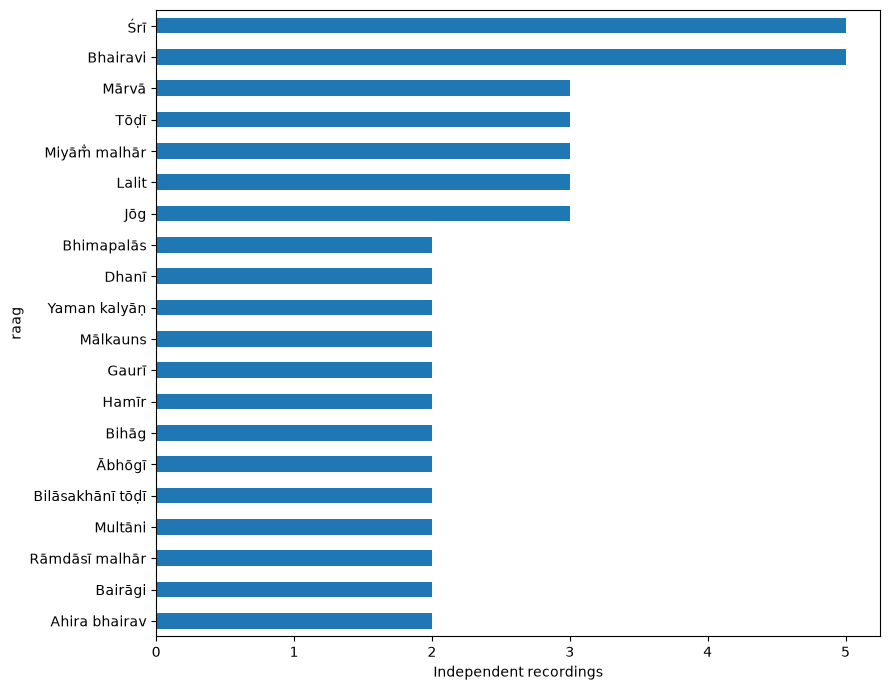

In [6]:
if "manifest" not in globals():
    raise RuntimeError("Run the recording metadata cell (tracks = dataset.load_tracks()) first.")

single_raag = manifest.loc[manifest.label_count == 1].copy()
single_raag["raag"] = single_raag.raag_names.map(lambda labels: labels[0])
single_raag["raag_id"] = single_raag.raag_ids.map(lambda labels: labels[0])
coverage = (
    single_raag.groupby(["raag_id", "raag"], dropna=False)
    .agg(recordings=("track_id", "size"),
         known_artists=("artists", lambda groups: len({a for group in groups for a in group})))
    .sort_values("recordings", ascending=False)
)
display(coverage)
if not coverage.empty:
    coverage.head(20).reset_index().plot.barh(x="raag", y="recordings", figsize=(9, 7), legend=False)
    plt.xlabel("Independent recordings")
    plt.gca().invert_yaxis()
    plt.tight_layout()
    plt.show()


## Listen to 30 seconds and view the provided pitch contour

Change the track ID or start time to explore other passages. This does not generate training windows.

Run both code cells under **Inspect recording metadata** before this cell. They create `tracks`, `manifest` and `single_raag`. After restarting the kernel, rerun setup and those two cells; you can skip the download if the data is already present.


/home/mushu/GitHub/MEIKURAL/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


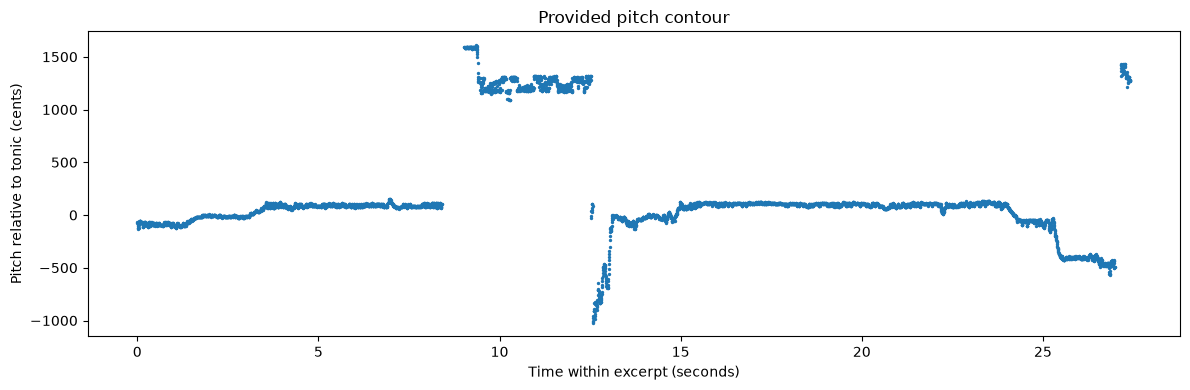

In [ ]:
import librosa
import numpy as np
from IPython.display import Audio, display

if "single_raag" not in globals():
    raise RuntimeError("Run the two cells under Inspect recording metadata first: the manifest cell, then the raag-coverage cell.")

if single_raag.empty:
    raise ValueError("No single-label recordings found. Inspect the metadata above.")
TRACK_ID = single_raag.iloc[0]["track_id"]
START_SECONDS = 60
track = tracks[TRACK_ID]
signal, sr = librosa.load(track.audio_path, sr=None, mono=True,
                          offset=START_SECONDS, duration=WINDOW_SECONDS)
if signal.size == 0:
    raise ValueError("Choose a smaller start time; this excerpt is empty.")
display(Audio(signal, rate=sr))
pitch = track.pitch
mask = ((pitch.times >= START_SECONDS)
        & (pitch.times < START_SECONDS + WINDOW_SECONDS)
        & (pitch.frequencies > 0))
cents = 1200 * np.log2(pitch.frequencies[mask] / track.tonic)
plt.figure(figsize=(12, 4))
plt.scatter(pitch.times[mask] - START_SECONDS, cents, s=2)
plt.xlabel("Time within excerpt (seconds)")
plt.ylabel("Pitch relative to tonic (cents)")
plt.title("Provided pitch contour")
plt.tight_layout()
plt.show()


## Before training

- Choose raags with enough independent recordings and artists for evaluation.
- Assign whole recordings to training, validation and testing before windowing. Keep artists/concerts separate where possible.
- Then create 30-second windows. A 15-second training stride gives 50% overlap; use a 30-second test stride initially.
- Filter silence, spoken introductions and unsuitable passages.
- Check recording IDs for duplicates before combining datasets.

Reusable implementation belongs in the empty Python files under `src/meikural/`.


## Total audio duration per raag

Run this cell independently from the repository root or `notebooks/`. It reads the raag labels from each recording's JSON metadata and plots total audio hours per raag, longest first. Unlabelled recordings are counted separately rather than guessed from folder names.

Durations are measured by decoding audio in small blocks, avoiding MP3 header-duration inaccuracies. This reads the full collection and may take a few minutes, but does not load it all into memory. Totals include the entire recordings, before silence/section filtering or 30-second windowing.


Measured 10/108 recordings
Measured 20/108 recordings
Measured 30/108 recordings
Measured 40/108 recordings


Note: Illegal Audio-MPEG-Header 0x44d3a352 at offset 54923548.
Note: Trying to resync...
Note: Skipped 244 bytes in input.


Measured 50/108 recordings
Measured 60/108 recordings
Measured 70/108 recordings
Measured 80/108 recordings
Measured 90/108 recordings
Measured 100/108 recordings
Measured 108/108 recordings
Labelled audio: 38.71 hours across 61 raags
Unassigned audio: 4.82 hours across 15 recordings
Total audio: 43.53 hours


,raag,recordings,minutes,hours
0,Śrī,5,267.395,4.457
1,Jōg,3,134.741,2.246
2,Miyām̐ malhār,3,122.112,2.035
3,Bihāg,2,107.622,1.794
4,Lalit,3,107.348,1.789
...,...,...,...,...
56,Dēś,1,6.448,0.107
57,Kalāvati,1,5.726,0.095
58,Mājh khamāj,1,5.393,0.090
59,Candrakauns,1,3.985,0.066


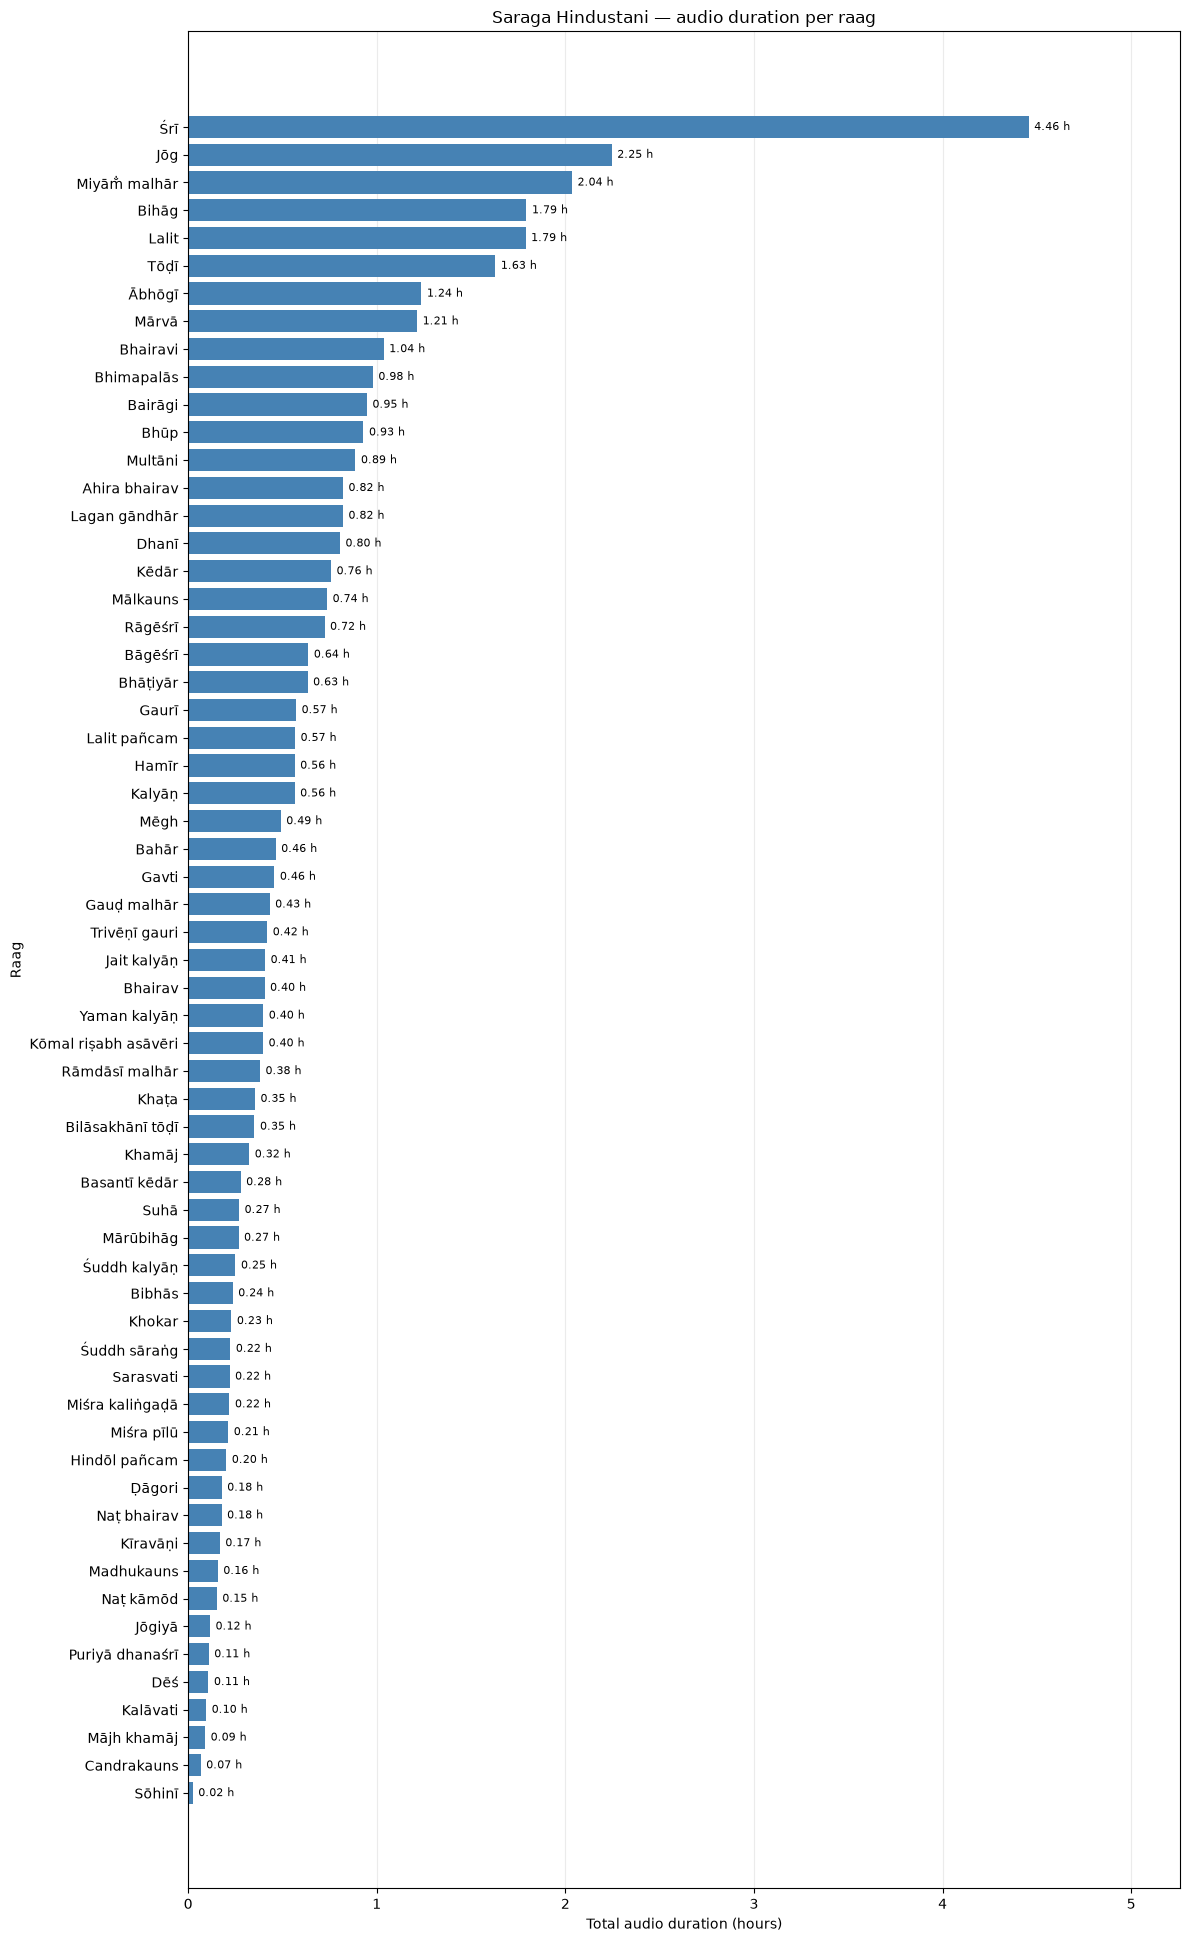

In [8]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import pandas as pd
import soundfile as sf
from IPython.display import display

project_root = Path.cwd().resolve()
if project_root.name == "notebooks":
    project_root = project_root.parent
collection_dir = (
    project_root / "data" / "raw" / "saraga_hindustani" / "saraga1.5_hindustani"
)
audio_paths = sorted(collection_dir.rglob("*.mp3"))
if not audio_paths:
    raise FileNotFoundError(f"No MP3 recordings found under {collection_dir}")

duration_rows = []
unassigned_rows = []
for index, audio_path in enumerate(audio_paths, start=1):
    metadata_paths = list(audio_path.parent.glob("*.json"))
    if len(metadata_paths) != 1:
        raise ValueError(f"Expected one metadata JSON beside {audio_path}")
    metadata = json.loads(metadata_paths[0].read_text())
    raags = metadata.get("raags") or []

    # Count decoded frames: channels do not multiply the recording duration.
    with sf.SoundFile(audio_path) as audio_file:
        sample_rate = audio_file.samplerate
        frame_count = sum(
            block.shape[0]
            for block in audio_file.blocks(
                blocksize=262144, dtype="float32", always_2d=True
            )
        )
    seconds = frame_count / sample_rate
    if len(raags) == 1:
        raag = raags[0]
        duration_rows.append({
            "raag_id": raag.get("uuid") or raag["name"],
            "raag": raag["name"],
            "seconds": seconds,
            "audio_path": str(audio_path.relative_to(project_root)),
        })
    else:
        unassigned_rows.append({
            "audio_path": str(audio_path.relative_to(project_root)),
            "seconds": seconds,
            "reason": "missing label" if not raags else "multiple labels",
        })
    if index % 10 == 0 or index == len(audio_paths):
        print(f"Measured {index}/{len(audio_paths)} recordings", flush=True)

if not duration_rows:
    raise ValueError("No recordings with exactly one raag label were found.")

recording_durations = pd.DataFrame(duration_rows)
duration_by_raag = (
    recording_durations.groupby(["raag_id", "raag"], as_index=False)
    .agg(recordings=("audio_path", "size"), seconds=("seconds", "sum"))
    .sort_values("seconds", ascending=False)
    .reset_index(drop=True)
)
duration_by_raag["minutes"] = duration_by_raag["seconds"] / 60
duration_by_raag["hours"] = duration_by_raag["seconds"] / 3600
unassigned_hours = sum(row["seconds"] for row in unassigned_rows) / 3600

print(f"Labelled audio: {duration_by_raag.hours.sum():.2f} hours across {len(duration_by_raag)} raags")
print(f"Unassigned audio: {unassigned_hours:.2f} hours across {len(unassigned_rows)} recordings")
print(f"Total audio: {duration_by_raag.hours.sum() + unassigned_hours:.2f} hours")
display(duration_by_raag[["raag", "recordings", "minutes", "hours"]].round(3))

fig, ax = plt.subplots(figsize=(12, max(6, len(duration_by_raag) * 0.32)))
positions = list(range(len(duration_by_raag)))
bars = ax.barh(positions, duration_by_raag["hours"], color="steelblue")
ax.set_yticks(positions, labels=duration_by_raag["raag"])
ax.invert_yaxis()
ax.set_xlabel("Total audio duration (hours)")
ax.set_ylabel("Raag")
ax.set_title("Saraga Hindustani — audio duration per raag")
ax.bar_label(bars, labels=[f"{hours:.2f} h" for hours in duration_by_raag.hours], padding=4, fontsize=8)
ax.set_xlim(0, duration_by_raag.hours.max() * 1.18)
ax.set_axisbelow(True)
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()


## Recording and artist counts per raag

This cell runs independently and reads metadata only, so it does not decode the audio again. Each audio file counts as one **recording**, not necessarily a distinct composition or independent performance. Artist counts use **album artists credited in the metadata**, deduplicated by MusicBrainz ID where available; these are a practical proxy for principal performers, not a count of all accompanists. Missing artist metadata is reported rather than guessed.

Noise augmentation can help robustness, but does not remove artist identity. Keep whole recordings in separate splits and evaluate on held-out artists where possible. Any Gaussian-noise augmentation should initially be training-only; inference uses the same feature preprocessing on the supplied audio without deliberately adding noise. Adding noise is not, by itself, a diffusion model.


Counted 93 labelled recordings across 61 raags.
Skipped 15 recordings with missing or multiple raag labels.
Recordings without album-artist metadata: 0


,raag,recordings,distinct_artists,recordings_without_artist_metadata,credited_artists
0,Bhairavi,5,4,0,Brajeshwar Mukherjee; Kaustuv Kanti Ganguli; O...
1,Śrī,5,4,0,Ajoy Chakrabarty; Deborshee Bhattacharya; Kaus...
2,Jōg,3,3,0,Ajoy Chakrabarty; Brajeshwar Mukherjee; Kaustu...
3,Lalit,3,3,0,Ajoy Chakrabarty; Kaustuv Kanti Ganguli; Omkar...
4,Miyām̐ malhār,3,3,0,Deborshee Bhattacharya; Kaustuv Kanti Ganguli;...
...,...,...,...,...,...
56,Sōhinī,1,1,0,Milind Malshe
57,Trivēṇī gauri,1,1,0,Milind Malshe
58,Śuddh kalyāṇ,1,1,0,Ajoy Chakrabarty
59,Śuddh sāraṅg,1,1,0,Ajoy Chakrabarty


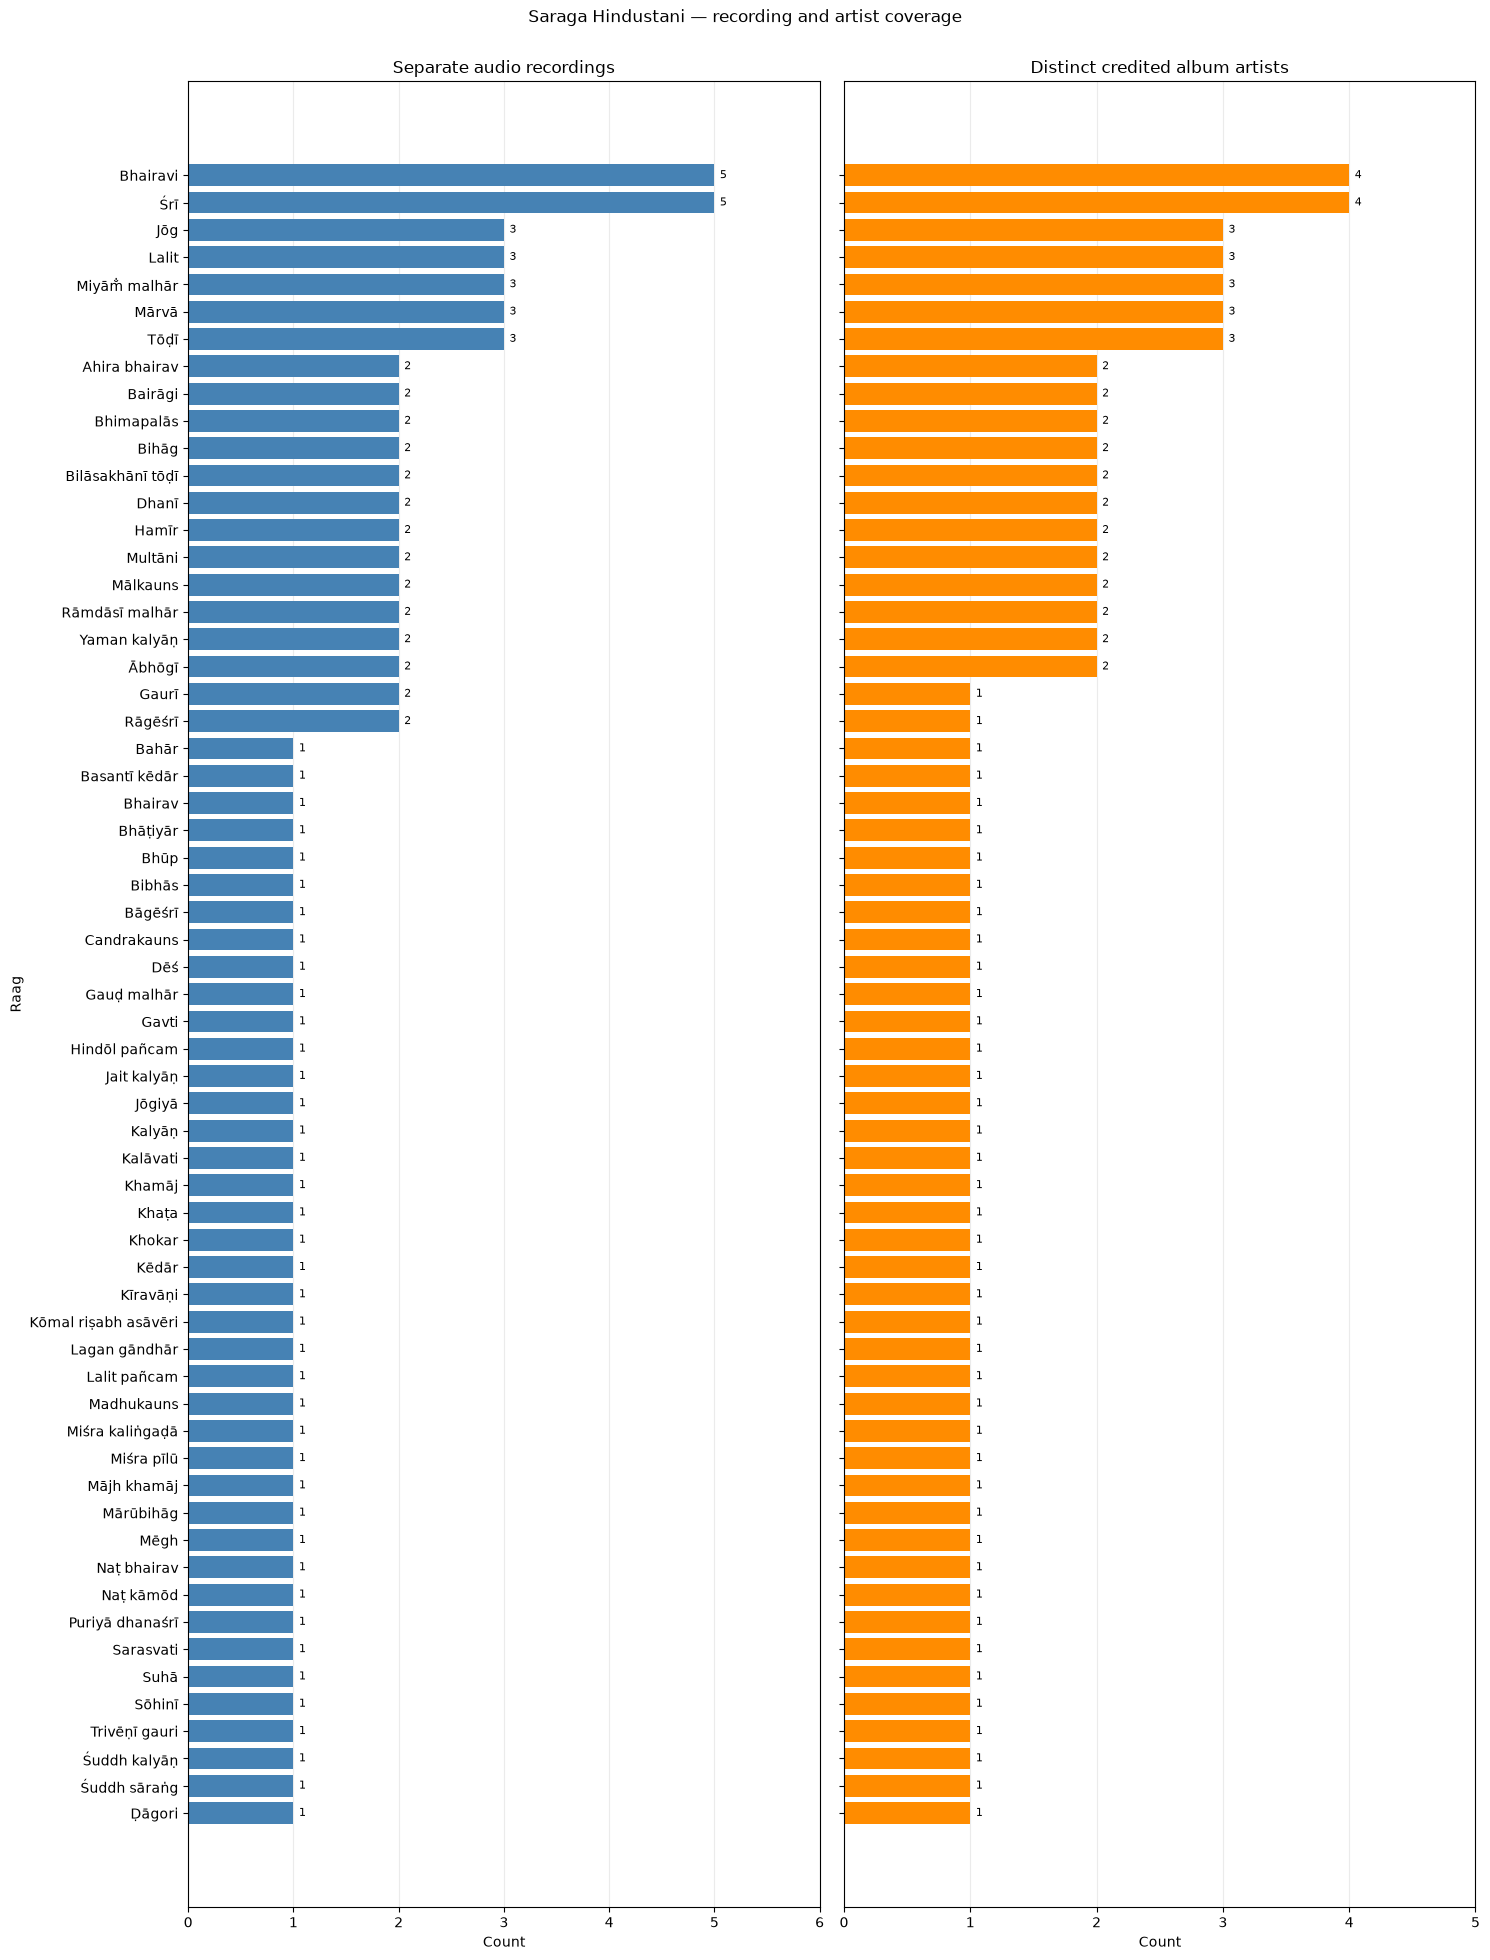

In [9]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import pandas as pd
from IPython.display import display

count_root = Path.cwd().resolve()
if count_root.name == "notebooks":
    count_root = count_root.parent
count_collection = (
    count_root / "data" / "raw" / "saraga_hindustani" / "saraga1.5_hindustani"
)
count_audio_paths = sorted(count_collection.rglob("*.mp3"))
if not count_audio_paths:
    raise FileNotFoundError(f"No MP3 recordings found under {count_collection}")

count_rows = []
skipped_label_count = 0
for audio_path in count_audio_paths:
    metadata_paths = list(audio_path.parent.glob("*.json"))
    if len(metadata_paths) != 1:
        raise ValueError(f"Expected one metadata JSON beside {audio_path}")
    metadata = json.loads(metadata_paths[0].read_text())
    raags = metadata.get("raags") or []
    if len(raags) != 1:
        skipped_label_count += 1
        continue
    raag = raags[0]
    artist_keys = set()
    artist_names = set()
    for artist in metadata.get("album_artists") or []:
        name = (artist.get("name") or "").strip()
        artist_id = artist.get("mbid") or artist.get("id")
        if artist_id:
            artist_keys.add("id:" + str(artist_id))
        elif name:
            artist_keys.add("name:" + name.casefold())
        if name:
            artist_names.add(name)
    count_rows.append({
        "raag_id": raag.get("uuid") or raag["name"],
        "raag": raag["name"],
        "audio_path": str(audio_path.relative_to(count_root)),
        "artist_keys": artist_keys,
        "artist_names": artist_names,
        "missing_artist_metadata": not artist_keys,
    })

if not count_rows:
    raise ValueError("No recordings with exactly one raag label were found.")

recording_artist_manifest = pd.DataFrame(count_rows)
recordings_artists_by_raag = (
    recording_artist_manifest.groupby(["raag_id", "raag"], as_index=False)
    .agg(
        recordings=("audio_path", "size"),
        distinct_artists=("artist_keys", lambda groups: len(set().union(*groups))),
        recordings_without_artist_metadata=("missing_artist_metadata", "sum"),
        credited_artists=("artist_names", lambda groups: "; ".join(sorted(set().union(*groups)))),
    )
    .sort_values(["recordings", "distinct_artists", "raag"], ascending=[False, False, True])
    .reset_index(drop=True)
)
print(f"Counted {len(count_rows)} labelled recordings across {len(recordings_artists_by_raag)} raags.")
print(f"Skipped {skipped_label_count} recordings with missing or multiple raag labels.")
print(f"Recordings without album-artist metadata: {recording_artist_manifest.missing_artist_metadata.sum()}")
display(recordings_artists_by_raag.drop(columns="raag_id"))

positions = list(range(len(recordings_artists_by_raag)))
fig, axes = plt.subplots(
    1, 2, figsize=(15, max(6, len(positions) * 0.32)), sharey=True
)
for ax, column, title, color in [
    (axes[0], "recordings", "Separate audio recordings", "steelblue"),
    (axes[1], "distinct_artists", "Distinct credited album artists", "darkorange"),
]:
    values = recordings_artists_by_raag[column]
    bars = ax.barh(positions, values, color=color)
    ax.bar_label(bars, padding=4, fontsize=8, fmt="%.0f")
    ax.set_title(title)
    ax.set_xlabel("Count")
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.set_xlim(0, max(1, values.max()) + 1)
    ax.set_axisbelow(True)
    ax.grid(axis="x", alpha=0.25)
axes[0].set_yticks(positions, labels=recordings_artists_by_raag["raag"])
axes[0].invert_yaxis()
axes[0].set_ylabel("Raag")
fig.suptitle("Saraga Hindustani — recording and artist coverage", y=1.002)
plt.tight_layout()
plt.show()


16 raags have at least 0.8 hours of audio.
Total audio in selected raags: 23.63 hours


,raag,hours,recordings,distinct_artists,recordings_without_artist_metadata,credited_artists
0,Śrī,4.457,5,4,0,Ajoy Chakrabarty; Deborshee Bhattacharya; Kaus...
1,Jōg,2.246,3,3,0,Ajoy Chakrabarty; Brajeshwar Mukherjee; Kaustu...
2,Miyām̐ malhār,2.035,3,3,0,Deborshee Bhattacharya; Kaustuv Kanti Ganguli;...
3,Bihāg,1.794,2,2,0,Deborshee Bhattacharya; Omkar Dadarkar
4,Lalit,1.789,3,3,0,Ajoy Chakrabarty; Kaustuv Kanti Ganguli; Omkar...
5,Tōḍī,1.629,3,3,0,Ajoy Chakrabarty; Kumar Gandharva; Omkar Dadarkar
6,Ābhōgī,1.237,2,2,0,Ajoy Chakrabarty; Anol Chatterjee
7,Mārvā,1.214,3,3,0,Kaustuv Kanti Ganguli; Omkar Dadarkar; Sameeha...
8,Bhairavi,1.037,5,4,0,Brajeshwar Mukherjee; Kaustuv Kanti Ganguli; O...
9,Bhimapalās,0.979,2,2,0,Omkar Dadarkar; Satyasheel Deshpande


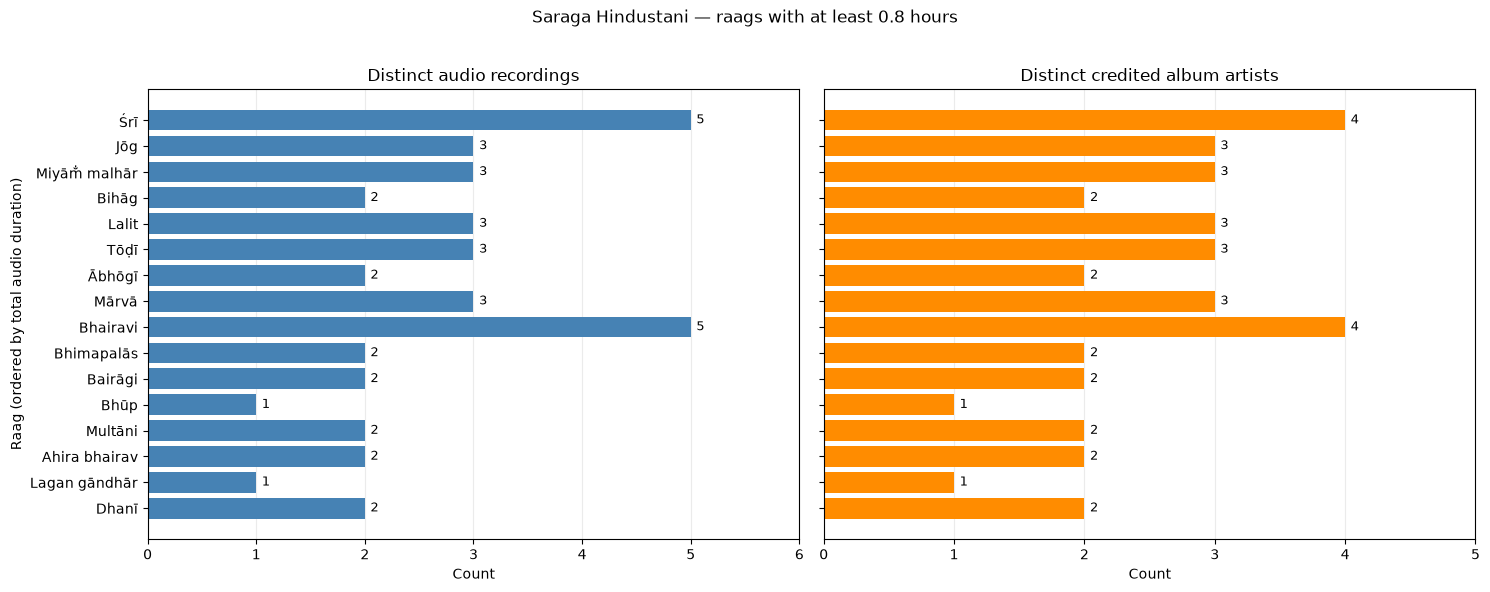

In [14]:
X_HOURS = 0.8  # <<< USER SETTING: minimum total audio hours per raag (inclusive)
# ============================================================================
# CHANGE X_HOURS ABOVE, THEN RERUN THIS CELL TO UPDATE THE TABLE AND BOTH PLOTS.
# Example: 0.5 includes raags with at least 30 minutes of labelled audio.
# Requires the preceding duration-summary and recording/artist-count cells.
# ============================================================================

import math
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from IPython.display import display

if isinstance(X_HOURS, bool) or not isinstance(X_HOURS, (int, float)):
    raise ValueError("X_HOURS must be a finite, nonnegative number.")
if not math.isfinite(X_HOURS) or X_HOURS < 0:
    raise ValueError("X_HOURS must be a finite, nonnegative number.")
if "duration_by_raag" not in globals() or "recordings_artists_by_raag" not in globals():
    raise RuntimeError(
        "Run the Total audio duration per raag cell and the Recording and artist "
        "counts per raag cell first."
    )

# Join on stable raag IDs rather than matching spelling variants.
threshold_coverage = recordings_artists_by_raag.merge(
    duration_by_raag[["raag_id", "hours"]],
    on="raag_id", how="outer", validate="one_to_one", indicator=True,
)
if not threshold_coverage["_merge"].eq("both").all():
    raise RuntimeError("The summaries cover different raags. Rerun both preceding summary cells.")
threshold_coverage = (
    threshold_coverage.loc[threshold_coverage.hours >= X_HOURS]
    .drop(columns="_merge")
    .sort_values(["hours", "raag"], ascending=[False, True])
    .reset_index(drop=True)
)

print(f"{len(threshold_coverage)} raags have at least {X_HOURS:g} hours of audio.")
if threshold_coverage.empty:
    print("No raags meet this threshold. Lower X_HOURS and rerun this cell.")
else:
    print(f"Total audio in selected raags: {threshold_coverage.hours.sum():.2f} hours")
    display(threshold_coverage[[
        "raag", "hours", "recordings", "distinct_artists",
        "recordings_without_artist_metadata", "credited_artists",
    ]].round({"hours": 3}))

    positions = list(range(len(threshold_coverage)))
    fig, axes = plt.subplots(
        1, 2, figsize=(15, max(4, len(positions) * 0.36)), sharey=True
    )
    for ax, column, title, color in [
        (axes[0], "recordings", "Distinct audio recordings", "steelblue"),
        (axes[1], "distinct_artists", "Distinct credited album artists", "darkorange"),
    ]:
        values = threshold_coverage[column]
        bars = ax.barh(positions, values, color=color)
        ax.bar_label(bars, padding=4, fontsize=9, fmt="%.0f")
        ax.set_title(title)
        ax.set_xlabel("Count")
        ax.xaxis.set_major_locator(MaxNLocator(integer=True))
        ax.set_xlim(0, max(1, values.max()) + 1)
        ax.set_axisbelow(True)
        ax.grid(axis="x", alpha=0.25)
    axes[0].set_yticks(positions, labels=threshold_coverage["raag"])
    axes[0].invert_yaxis()
    axes[0].set_ylabel("Raag (ordered by total audio duration)")
    fig.suptitle(f"Saraga Hindustani — raags with at least {X_HOURS:g} hours", y=1.02)
    plt.tight_layout()
    plt.show()
